(what-bill-to-reserve)=
# Medical spending reserves

The RAND Health Insurance Experiment assigned the share of the bill a family paid. A desk that has to reserve for the covered spending of someone already enrolled is not estimating a visit count and not fitting a binary "any use" model on its own. In study year 2, about 23% of people have no covered spending at all. The rest have a right-skewed bill. The reserve is the expected dollars, which is the probability of a bill times the expected size of a positive bill.

The file is the Cameron and Trivedi (2005) extract of the experiment, R package `sampleSelection::RandHIE`, retrieved 2026-10-04 from `https://vincentarelbundock.github.io/Rdatasets/csv/sampleSelection/RandHIE.csv`. Rows are study year 2 with the household head's education observed, the subsample in section 16.6 of that book. Nineteen people with an incomplete inpatient record (`inpmis` = 1) are omitted. `meddol` is covered inpatient and outpatient spending in constant dollars, excluding dental care and outpatient psychotherapy. The plan enters as the extract's own transforms: `logc`, `idp`, `lpi` and `fmde`. On the coinsurance plans (`idp` = 0), `logc` equals log(coins + 1). It does not on the individual deductible plan.

The candidates are a two-part constant, a logit plus a gamma for the positive bill, a logit plus a lognormal, the same two splits with boosting, a zero-adjusted gamma that fits the zero and the positive bill together, a Gaussian mean, and a Tweedie mean. Steps are chosen on people held out by whether the bill is zero. The mixed log score is the negative mean log probability of an exact zero, or of the positive density when the bill is positive. A Gaussian or a Tweedie mean has no atom, so it is scored only by the dollar error.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | expected covered medical spending in study year 2 |
| **Observed response** | `meddol`, dollars, with a point mass at zero |
| **Estimand** | held-out mixed log score, and mean absolute error of the expected dollars |
| **Units** | nats per person; dollars |
| **Sampling unit** | one row is one enrolled person with spending in study year 2 |
| **Dependence** | The working likelihood treats person records as conditionally independent; no family or plan cluster adjustment is estimated. |
| **Split and tuning** | people, stratified by a zero bill; 20% choose steps, 20% held out, refit on the rest |
| **Information** | the plan transforms in the extract, health, and demographics |
| **Uncertainty** | fitted predictive distributions are scored; no resampling confidence intervals for score differences are reported |
| **Claim type** | predictive comparisons conditional on the recorded covariates; no causal effects are estimated |
| **What this does not estimate** | a premium, a visit count, or a bill for someone the experiment never enrolled |

:::


In [1]:
import warnings
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import optimize, stats
from sklearn.linear_model import TweedieRegressor

import mboostrs as mb

path = Path("rand_hie_year2.csv")
if not path.exists():
    path = Path("docs/book/case_studies/rand_hie_year2.csv")
raw = pl.read_csv(path, comment_prefix="#")
frame = raw.with_columns([pl.col(c).cast(pl.Float64) for c in raw.columns if c != "zper"])
predictors = [
    "logc", "idp", "lpi", "fmde", "physlm", "disea", "hlthg", "hlthf", "hlthp",
    "linc", "lfam", "educdec", "xage", "female", "child", "fchild", "black",
]
rhs = " + ".join(predictors)
spend = "meddol ~ " + rhs
hurdle = "any_bill ~ " + rhs
frame = frame.with_columns((pl.col("meddol") > 0).cast(pl.Float64).alias("any_bill"))

rng = np.random.default_rng(20261004)
indexed = frame.with_row_index("i")
parts = []
for flag in (0.0, 1.0):
    ids = indexed.filter(pl.col("any_bill") == flag)["i"].to_numpy().copy()
    rng.shuffle(ids)
    n = len(ids)
    n_test = int(round(0.20 * n))
    n_valid = int(round(0.20 * n))
    parts.append((ids[n_test + n_valid :], ids[n_test : n_test + n_valid], ids[:n_test]))
train_ids = np.concatenate([p[0] for p in parts])
valid_ids = np.concatenate([p[1] for p in parts])
test_ids = np.concatenate([p[2] for p in parts])
train = frame[train_ids.tolist()]
valid = frame[valid_ids.tolist()]
fit_rows = frame[np.concatenate([train_ids, valid_ids]).tolist()]
test = frame[test_ids.tolist()]
print(
    f"{frame.height} people, {int((frame['meddol'] == 0).sum())} with no covered spending; "
    f"{train.height} to fit the path, {valid.height} to choose steps, "
    f"{fit_rows.height} refit, {test.height} held out"
)


5555 people, 1290 with no covered spending; 3333 to fit the path, 1111 to choose steps, 4444 refit, 1111 held out


In [2]:
def columns_of(data):
    return {name: data[name].to_numpy() for name in data.columns}


def mae(y, mu):
    return float(np.mean(np.abs(np.asarray(y, dtype=float) - np.asarray(mu, dtype=float))))


def mixed_log_score(y, p_zero, positive_logpdf):
    y = np.asarray(y, dtype=float)
    p0 = np.clip(np.asarray(p_zero, dtype=float), 1e-12, 1.0 - 1e-12)
    zero = y == 0.0
    score = np.empty(len(y))
    score[zero] = np.log(p0[zero])
    score[~zero] = np.log(1.0 - p0[~zero]) + np.asarray(positive_logpdf, dtype=float)[~zero]
    return float(-np.mean(score))


def gamma_shape(y, mu):
    def objective(log_shape):
        shape = np.exp(log_shape)
        return -np.sum(stats.gamma.logpdf(y, a=shape, scale=mu / shape))

    fit = optimize.minimize_scalar(objective, bounds=(-4.0, 4.0), method="bounded")
    return float(np.exp(fit.x))


y_test = test["meddol"].to_numpy()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    logit = smf.logit(hurdle, columns_of(fit_rows)).fit(disp=False)
    positive = fit_rows.filter(pl.col("meddol") > 0)
    gamma = smf.glm(
        spend, columns_of(positive), family=sm.families.Gamma(link=sm.families.links.Log())
    ).fit()
    logged = {**columns_of(positive), "log_med": np.log(positive["meddol"].to_numpy())}
    lognormal = smf.ols("log_med ~ " + rhs, logged).fit()
    ols = smf.ols(spend, columns_of(fit_rows)).fit()
    tweedie = TweedieRegressor(power=1.5, alpha=0.0, link="log", max_iter=1000)
    tweedie.fit(fit_rows.select(predictors).to_numpy(), fit_rows["meddol"].to_numpy())

logit_p = np.asarray(logit.predict(columns_of(test)), dtype=float)
gamma_mu = np.asarray(gamma.predict(columns_of(test)), dtype=float)
gamma_mu_fit = np.asarray(gamma.predict(columns_of(positive)), dtype=float)
shape_mle = gamma_shape(positive["meddol"].to_numpy(), gamma_mu_fit)
shape_pearson = 1.0 / float(gamma.scale)
log_mu = np.asarray(lognormal.predict(columns_of(test)), dtype=float)
sigma_ln = float(np.sqrt(lognormal.scale))
ols_mu = np.asarray(ols.predict(columns_of(test)), dtype=float)
tweedie_mu = np.asarray(tweedie.predict(test.select(predictors).to_numpy()), dtype=float)

p_bar = float(fit_rows["any_bill"].mean())
positive_y = positive["meddol"].to_numpy()
log_bar = float(np.mean(np.log(positive_y)))
sigma_bar = float(np.std(np.log(positive_y), ddof=0))
a_bar, _loc, scale_bar = stats.gamma.fit(positive_y, floc=0)
logit_converged = bool(logit.mle_retvals.get("converged"))


In [3]:
def operating_step(curve, tolerance):
    best = min(score for _, score in curve)
    step = min(s for s, score in curve if score <= best + tolerance)
    last_step, last_score = curve[-1]
    earlier = [score for s, score in curve if s <= last_step - 80]
    still_falling = bool(earlier) and earlier[-1] - last_score > 0.01 and last_score <= best + 1e-12
    return step, best, still_falling


def tune_glm(formula, data_fit, data_valid, family, score_of, cap, step, tolerance):
    path = mb.glmboost(formula, data_fit, family=family, control=mb.boost_control(cap, 0.1))
    curve = []
    for k in range(step, cap + 1, step):
        model = path.with_mstop(k)
        pred = np.asarray(model.predict(data_valid, type="response"), dtype=float).ravel()
        curve.append((k, score_of(pred, model)))
    return operating_step(curve, tolerance)


y_valid = valid["meddol"].to_numpy()
any_valid = valid["any_bill"].to_numpy()
pos_train = train.filter(pl.col("meddol") > 0)
pos_valid = valid.filter(pl.col("meddol") > 0)
y_pos_valid = pos_valid["meddol"].to_numpy()


def binomial_score(pred, model):
    p = np.clip(pred, 1e-6, 1.0 - 1e-6)
    return float(-np.mean(any_valid * np.log(p) + (1.0 - any_valid) * np.log(1.0 - p)))


def gamma_score(pred, model):
    shape = float(np.asarray(model.nuisance()).ravel()[0])
    return float(-np.mean(stats.gamma.logpdf(y_pos_valid, a=shape, scale=pred / shape)))


def lognormal_score(pred, model):
    fitted = np.asarray(model.predict(type="response"), dtype=float).ravel()
    sigma = float(np.sqrt(np.mean((np.log(pos_train["meddol"].to_numpy()) - fitted) ** 2)))
    return float(-np.mean(stats.lognorm.logpdf(y_pos_valid, s=sigma, scale=np.exp(pred))))


def gaussian_score(pred, model):
    return mae(y_valid, pred)


step_bin, _, bin_at_cap = tune_glm(
    hurdle, train, valid, mb.Binomial(), binomial_score, 400, 20, 0.005
)
step_gamma, _, gamma_at_cap = tune_glm(
    spend, pos_train, pos_valid, mb.GammaReg(), gamma_score, 400, 20, 0.005
)
log_formula = "log_med ~ " + rhs
step_log, _, log_at_cap = tune_glm(
    log_formula,
    pos_train.with_columns(pl.col("meddol").log().alias("log_med")),
    pos_valid.with_columns(pl.col("meddol").log().alias("log_med")),
    mb.Gaussian(),
    lognormal_score,
    400,
    20,
    0.005,
)
step_gauss, _, gauss_at_cap = tune_glm(
    spend, train, valid, mb.Gaussian(), gaussian_score, 200, 10, 0.0
)

zaga = mb.ZeroAdjustedGammaLSS()
lss_curve = []
for k in range(40, 401, 40):
    cold = mb.glmboostLSS(spend, train, families=zaga, control=mb.boost_control(k, 0.1))
    params = cold.predict(valid, type="response")
    density = zaga.pdf(y_valid, params)
    lss_curve.append((k, float(-np.mean(np.log(np.clip(density, 1e-300, None))))))
step_lss, _, lss_at_cap = operating_step(lss_curve, 0.005)
print(
    "steps",
    {"binomial": step_bin, "gamma": step_gamma, "lognormal": step_log, "gaussian": step_gauss, "zaga": step_lss},
)
print("still falling at the cap", {"binomial": bin_at_cap, "gamma": gamma_at_cap, "lognormal": log_at_cap, "gaussian": gauss_at_cap, "zaga": lss_at_cap})


steps {'binomial': 100, 'gamma': 220, 'lognormal': 80, 'gaussian': 70, 'zaga': 320}
still falling at the cap {'binomial': False, 'gamma': False, 'lognormal': False, 'gaussian': False, 'zaga': False}


In [4]:
bin_fit = mb.glmboost(hurdle, fit_rows, family=mb.Binomial(), control=mb.boost_control(step_bin, 0.1))
p_boost = np.asarray(bin_fit.predict(test, type="response"), dtype=float).ravel()
gam_fit = mb.glmboost(
    spend,
    fit_rows.filter(pl.col("meddol") > 0),
    family=mb.GammaReg(),
    control=mb.boost_control(step_gamma, 0.1),
)
mu_gamma_boost = np.asarray(gam_fit.predict(test, type="response"), dtype=float).ravel()
shape_boost = float(np.asarray(gam_fit.nuisance()).ravel()[0])
log_fit_rows = fit_rows.filter(pl.col("meddol") > 0).with_columns(pl.col("meddol").log().alias("log_med"))
log_fit = mb.glmboost(log_formula, log_fit_rows, family=mb.Gaussian(), control=mb.boost_control(step_log, 0.1))
mu_log_boost = np.asarray(log_fit.predict(test, type="response"), dtype=float).ravel()
sigma_boost = float(np.sqrt(np.mean((log_fit_rows["log_med"].to_numpy() - np.asarray(log_fit.predict(type="response"), dtype=float).ravel()) ** 2)))
gauss_fit = mb.glmboost(spend, fit_rows, family=mb.Gaussian(), control=mb.boost_control(step_gauss, 0.1))
mu_gauss = np.asarray(gauss_fit.predict(test, type="response"), dtype=float).ravel()
lss_fit = mb.glmboostLSS(spend, fit_rows, families=zaga, control=mb.boost_control(step_lss, 0.1))
lss_test = lss_fit.predict(test, type="response")
lss_mean = (1.0 - lss_test["nu"]) * lss_test["mu"]

rows = []


def add(method, log_score, error, mstop=None, at_cap=None, note=""):
    rows.append({
        "method": method,
        "log_score": log_score,
        "mae": error,
        "mstop": mstop,
        "at_cap": at_cap,
        "note": note,
    })


add(
    "constant lognormal",
    mixed_log_score(y_test, np.full(len(y_test), 1.0 - p_bar), stats.lognorm.logpdf(y_test, s=sigma_bar, scale=np.exp(log_bar))),
    mae(y_test, np.full(len(y_test), p_bar * np.exp(log_bar + 0.5 * sigma_bar**2))),
    note=f"positive rate {p_bar:.3f}",
)
add(
    "constant gamma",
    mixed_log_score(y_test, np.full(len(y_test), 1.0 - p_bar), stats.gamma.logpdf(y_test, a=a_bar, scale=scale_bar)),
    mae(y_test, np.full(len(y_test), p_bar * a_bar * scale_bar)),
    note="shape fit to the positive bills",
)
add(
    "logit + gamma",
    mixed_log_score(y_test, 1.0 - logit_p, stats.gamma.logpdf(y_test, a=shape_mle, scale=gamma_mu / shape_mle)),
    mae(y_test, logit_p * gamma_mu),
    note=f"logit converged {logit_converged}; shape {shape_mle:.3f}, Pearson shape {shape_pearson:.3f}",
)
add(
    "logit + lognormal",
    mixed_log_score(y_test, 1.0 - logit_p, stats.lognorm.logpdf(y_test, s=sigma_ln, scale=np.exp(log_mu))),
    mae(y_test, logit_p * np.exp(log_mu + 0.5 * sigma_ln**2)),
    note=f"sigma {sigma_ln:.3f}",
)
add(
    "boosted logit + gamma",
    mixed_log_score(y_test, 1.0 - p_boost, stats.gamma.logpdf(y_test, a=shape_boost, scale=mu_gamma_boost / shape_boost)),
    mae(y_test, p_boost * mu_gamma_boost),
    mstop=step_gamma,
    at_cap=gamma_at_cap,
    note=f"hurdle mstop {step_bin}; shape {shape_boost:.3f}",
)
add(
    "boosted logit + lognormal",
    mixed_log_score(y_test, 1.0 - p_boost, stats.lognorm.logpdf(y_test, s=sigma_boost, scale=np.exp(mu_log_boost))),
    mae(y_test, p_boost * np.exp(mu_log_boost + 0.5 * sigma_boost**2)),
    mstop=step_log,
    at_cap=log_at_cap,
    note=f"hurdle mstop {step_bin}; sigma {sigma_boost:.3f}",
)
add(
    "glmboostLSS zero-adjusted gamma",
    float(-np.mean(np.log(np.clip(zaga.pdf(y_test, lss_test), 1e-300, None)))),
    mae(y_test, lss_mean),
    mstop=step_lss,
    at_cap=lss_at_cap,
    note="nu is the probability of a zero",
)
add("statsmodels OLS", None, mae(y_test, ols_mu), note=f"negative means {float((ols_mu < 0).mean()):.3f}")
add("sklearn Tweedie power 1.5", None, mae(y_test, tweedie_mu), note="no penalty; mean only")
add(
    "glmboost Gaussian",
    None,
    mae(y_test, mu_gauss),
    mstop=step_gauss,
    at_cap=gauss_at_cap,
    note=f"negative means {float((mu_gauss < 0).mean()):.3f}",
)
summary = pl.DataFrame(rows).sort("log_score", nulls_last=True)
display(summary)


method,log_score,mae,mstop,at_cap,note
str,f64,f64,i64,bool,str
"""logit + lognormal""",4.967629,176.170045,null,null,"""sigma 1.382"""
"""boosted logit + lognormal""",4.973513,169.107382,80,false,"""hurdle mstop 100; sigma 1.389"""
"""constant lognormal""",5.068127,186.669171,null,null,"""positive rate 0.768"""
"""logit + gamma""",5.14534,204.700909,null,null,"""logit converged True; shape 0.…"
"""boosted logit + gamma""",5.146579,197.057179,220,false,"""hurdle mstop 100; shape 0.561"""
"""glmboostLSS zero-adjusted gamm…",5.152371,195.610202,320,false,"""nu is the probability of a zer…"
"""constant gamma""",5.229078,209.83535,null,null,"""shape fit to the positive bill…"
"""statsmodels OLS""",null,208.720242,null,null,"""negative means 0.060"""
"""sklearn Tweedie power 1.5""",null,201.523495,null,null,"""no penalty; mean only"""


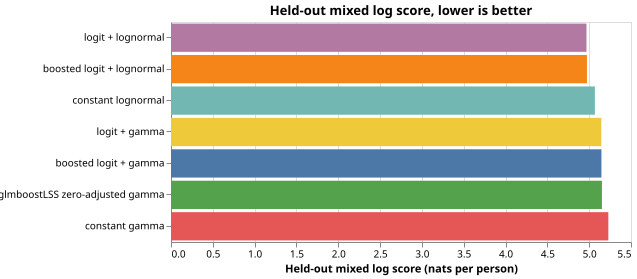

In [5]:
scored = summary.filter(pl.col("log_score").is_not_null())
alt.Chart(scored).mark_bar().encode(
    x=alt.X("log_score:Q", title="Held-out mixed log score (nats per person)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=460,
    height=220,
    title="Held-out mixed log score, lower is better",
)


plan,p_bill,reserve
str,f64,f64
"""free care""",0.835694,173.628617
"""25% coinsurance""",0.774653,116.353021
"""50% coinsurance""",0.752452,115.784047
"""95% coinsurance""",0.726438,116.231971
"""individual deductible""",0.676469,101.204348


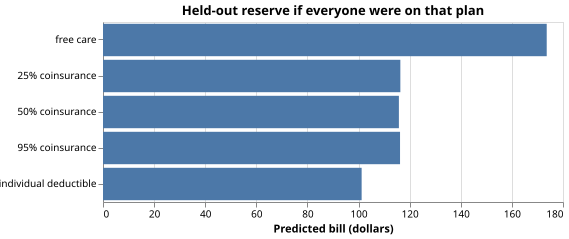

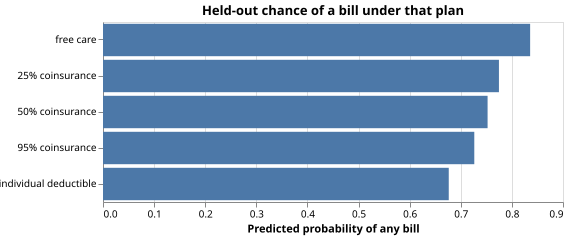

In [6]:
# Coinsurance plans are one code each. The individual deductible is not: most of
# those rows share the 95% plan's logc, and a few dozen are coded differently.
# The contrast uses the modal deductible cell, and plan terms from the refit sample.
plan_rows = fit_rows.with_columns(
    pl.when((pl.col("idp") == 1) & (pl.col("logc") > 1))
    .then(pl.lit("individual deductible"))
    .when((pl.col("idp") == 0) & (pl.col("coins") == 0))
    .then(pl.lit("free care"))
    .when((pl.col("idp") == 0) & (pl.col("coins") == 25))
    .then(pl.lit("25% coinsurance"))
    .when((pl.col("idp") == 0) & (pl.col("coins") == 50))
    .then(pl.lit("50% coinsurance"))
    .when((pl.col("idp") == 0) & (pl.col("coins") == 95))
    .then(pl.lit("95% coinsurance"))
    .otherwise(pl.lit(None))
    .alias("plan")
).filter(pl.col("plan").is_not_null())
terms = plan_rows.group_by("plan").agg(
    pl.col("logc").median(),
    pl.col("idp").median(),
    pl.col("fmde").median(),
    pl.col("lpi").median(),
)
order = ["free care", "25% coinsurance", "50% coinsurance", "95% coinsurance", "individual deductible"]
contrast = []
for plan in order:
    term = terms.filter(pl.col("plan") == plan)
    shifted = test.with_columns(
        pl.lit(float(term["logc"][0])).alias("logc"),
        pl.lit(float(term["idp"][0])).alias("idp"),
        pl.lit(float(term["fmde"][0])).alias("fmde"),
        pl.lit(float(term["lpi"][0])).alias("lpi"),
    )
    p = np.asarray(logit.predict(columns_of(shifted)), dtype=float)
    loc = np.asarray(lognormal.predict(columns_of(shifted)), dtype=float)
    contrast.append({
        "plan": plan,
        "p_bill": float(np.mean(p)),
        "reserve": float(np.mean(p * np.exp(loc + 0.5 * sigma_ln**2))),
    })
contrast_frame = pl.DataFrame(contrast)
display(contrast_frame)
reserve_chart = alt.Chart(contrast_frame).mark_bar().encode(
    x=alt.X("reserve:Q", title="Predicted bill (dollars)"),
    y=alt.Y("plan:N", sort=order, title=None),
).properties(width=460, height=180, title="Held-out reserve if everyone were on that plan")
chance_chart = alt.Chart(contrast_frame).mark_bar().encode(
    x=alt.X("p_bill:Q", title="Predicted probability of any bill"),
    y=alt.Y("plan:N", sort=order, title=None),
).properties(width=460, height=180, title="Held-out chance of a bill under that plan")
display(reserve_chart)
display(chance_chart)


## Results and interpretation

Publish the logit plus the lognormal. On the held-out people its mixed log score is {eval}`f"{float(summary.filter(pl.col('method')=='logit + lognormal')['log_score'][0]):.3f}"` nats and its mean absolute error is {eval}`f"{float(summary.filter(pl.col('method')=='logit + lognormal')['mae'][0]):.0f}"` dollars. The constant lognormal, which keeps the same shape and ignores the plan and the person, scores {eval}`f"{float(summary.filter(pl.col('method')=='constant lognormal')['log_score'][0]):.3f}"`. The covariates are worth that gap, about a tenth of a nat, and about {eval}`f"{float(summary.filter(pl.col('method')=='constant lognormal')['mae'][0]) - float(summary.filter(pl.col('method')=='logit + lognormal')['mae'][0]):.0f}"` dollars of absolute error. The boosted lognormal scores {eval}`f"{float(summary.filter(pl.col('method')=='boosted logit + lognormal')['log_score'][0]):.3f}"` at {eval}`str(int(summary.filter(pl.col('method')=='boosted logit + lognormal')['mstop'][0]))` steps, and its absolute error is {eval}`f"{float(summary.filter(pl.col('method')=='boosted logit + lognormal')['mae'][0]):.0f}"` dollars. The density picks the closed form. The dollar gap is not a reason to leave it.

Do not publish a gamma. With the covariates it scores {eval}`f"{float(summary.filter(pl.col('method')=='logit + gamma')['log_score'][0]):.3f}"`, worse than the constant lognormal. The shape that maximises the gamma likelihood at those means is about {eval}`f"{shape_mle:.2f}"`. The Pearson dispersion the GLM reports implies a shape of about {eval}`f"{shape_pearson:.2f}"`. Either way the positive bills are heavier than a gamma. Boosting the gamma, or fitting the zero and the gamma together (`glmboostLSS` zero-adjusted gamma, {eval}`str(int(summary.filter(pl.col('method')=='glmboostLSS zero-adjusted gamma')['mstop'][0]))` steps, score {eval}`f"{float(summary.filter(pl.col('method')=='glmboostLSS zero-adjusted gamma')['log_score'][0]):.3f}"`), does not repair the shape. The constant gamma is {eval}`f"{float(summary.filter(pl.col('method')=='constant gamma')['log_score'][0]):.3f}"`.

`logc` is in the chance of a bill and not in the size of a positive bill. Its logit coefficient is {eval}`f"{float(logit.params['logc']):.3f}"` (standard error {eval}`f"{float(logit.bse['logc']):.3f}"`) and its lognormal coefficient is {eval}`f"{float(lognormal.params['logc']):.3f}"` (standard error {eval}`f"{float(lognormal.bse['logc']):.3f}"`). The reserve still falls when the whole free-care package is replaced by a coinsurance package, because that package also changes `fmde`, the maximum-dollar offer. `fmde` is zero on free care and about 7 to 8 on the coinsurance plans, and its lognormal coefficient is {eval}`f"{float(lognormal.params['fmde']):.3f}"` (standard error {eval}`f"{float(lognormal.bse['fmde']):.3f}"`). Giving every held-out person the free-care terms, the model reserves {eval}`f"{float(contrast_frame.filter(pl.col('plan')=='free care')['reserve'][0]):.0f}"` dollars and puts the chance of a bill at {eval}`f"{float(contrast_frame.filter(pl.col('plan')=='free care')['p_bill'][0]):.0%}"`. The same people on the 25%, 50% and 95% terms are reserved at about {eval}`f"{float(contrast_frame.filter(pl.col('plan')=='95% coinsurance')['reserve'][0]):.0f}"` dollars. The chance keeps falling, from {eval}`f"{float(contrast_frame.filter(pl.col('plan')=='25% coinsurance')['p_bill'][0]):.0%}"` at 25% to {eval}`f"{float(contrast_frame.filter(pl.col('plan')=='95% coinsurance')['p_bill'][0]):.0%}"` at 95%. The raw mean in the 50% cell is not that gradient; one tail pulls the cell mean around. Use the model's reserve.

The individual deductible is not a coinsurance rate. Most of those rows are coded with `logc` equal to the 95% plan and a lower `fmde`; the rest, a few hundred rows, are coded differently and are not in the chart. On the modal coding the held-out reserve is {eval}`f"{float(contrast_frame.filter(pl.col('plan')=='individual deductible')['reserve'][0]):.0f}"` dollars and the chance of a bill is {eval}`f"{float(contrast_frame.filter(pl.col('plan')=='individual deductible')['p_bill'][0]):.0%}"`.

A woman is more likely to have a bill, and the positive bill is larger. The logit coefficient on `female` is {eval}`f"{float(logit.params['female']):.2f}"` (standard error {eval}`f"{float(logit.bse['female']):.2f}"`) and the lognormal coefficient is {eval}`f"{float(lognormal.params['female']):.2f}"` (standard error {eval}`f"{float(lognormal.bse['female']):.2f}"`). That is a different reserve, not a different family.

Do not publish the OLS mean or the Gaussian boost. They have no atom at zero, and {eval}`f"{float((ols_mu < 0).mean()):.1%}"` and {eval}`f"{float((mu_gauss < 0).mean()):.1%}"` of their held-out means are negative. The Tweedie mean (power 1.5, no penalty) stays non-negative and its absolute error is {eval}`f"{float(summary.filter(pl.col('method')=='sklearn Tweedie power 1.5')['mae'][0]):.0f}"` dollars, still short of the lognormal, and it does not give a probability of no bill to put next to the reserve.

This is covered spending in study year 2 for someone already enrolled, excluding dental care and outpatient psychotherapy. It is not a premium and not a person the experiment never enrolled. The source extract includes people eligible for only part of the year. Their bill is what was covered during eligibility, not an annualized rate.


In [7]:
link = np.asarray(bin_fit.predict(type="link"), dtype=float).ravel()
response = np.asarray(bin_fit.predict(type="response"), dtype=float).ravel()
half_logit_gap = float(np.max(np.abs(response - 1.0 / (1.0 + np.exp(-2.0 * link)))))
y_fit = fit_rows["any_bill"].to_numpy()
bernoulli = float(np.sum(
    y_fit * np.log(np.clip(response, 1e-12, 1.0))
    + (1.0 - y_fit) * np.log(np.clip(1.0 - response, 1e-12, 1.0))
))
binomial_ll_gap = abs(float(bin_fit.logLik()) - bernoulli)
train_params = lss_fit.predict(type="response")
hand_lss = float(np.sum(np.log(np.clip(zaga.pdf(fit_rows["meddol"].to_numpy(), train_params), 1e-300, None))))
lss_ll_gap = abs(float(lss_fit.logLik()) - hand_lss)
mu_pos = np.asarray(gam_fit.predict(type="response"), dtype=float).ravel()
hand_gamma = float(np.sum(stats.gamma.logpdf(
    fit_rows.filter(pl.col("meddol") > 0)["meddol"].to_numpy(),
    a=shape_boost,
    scale=mu_pos / shape_boost,
)))
gamma_ll_gap = abs(float(gam_fit.logLik()) - hand_gamma)
mean_gap = float(np.max(np.abs(zaga.mean(train_params) - (1.0 - train_params["nu"]) * train_params["mu"])))
print("half-logit", half_logit_gap)
print("binomial logLik", binomial_ll_gap)
print("zaga logLik", lss_ll_gap)
print("gamma logLik", gamma_ll_gap)
print("zaga mean", mean_gap)
print("caps", bin_at_cap, gamma_at_cap, log_at_cap, gauss_at_cap, lss_at_cap)


half-logit 0.0
binomial logLik 9.094947017729282e-13
zaga logLik 2.1827872842550278e-11
gamma logLik 1.0913936421275139e-11
zaga mean 0.0
caps False False False False False


## API behavior and limitations

`Binomial` `predict` with no `type` is half the log-odds. `type="response"` is `1 / (1 + exp(-2 f))`, and on this fit that matches the response to {eval}`f"{half_logit_gap:.1e}"`. `logLik()` matches the Bernoulli likelihood of that probability to {eval}`f"{binomial_ll_gap:.1e}"`.

For the zero-adjusted gamma, `nu` is the probability of an exact zero and the unconditional mean is `(1 - nu) * mu`. `pdf` at a zero is that probability, not a density; above zero it is `(1 - nu)` times the gamma density. `logLik()` matches the sum of the log of that `pdf` to {eval}`f"{lss_ll_gap:.1e}"`, and `mean()` matches `(1 - nu) * mu` to {eval}`f"{mean_gap:.1e}"`. The mixed log score uses that same number. It is not comparable to a Gaussian log density, which has no atom.

`GammaReg.nuisance()` is the gamma shape. `predict(type="response")` is `exp(f)`, the mean of a positive bill. `logLik()` matches that gamma density to {eval}`f"{gamma_ll_gap:.1e}"`. The logit-plus-gamma row is scored at the shape that maximises the likelihood given those means. The Pearson shape in the note is the GLM dispersion, and it is a different number.
